In [ ]:
from pathlib import Path
from urllib.request import urlretrieve
from zipfile import ZipFile

In [ ]:
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

In [ ]:
DATASET_URL = ("https://storage.googleapis.com/tensorflow-1-public/course2/cats_and_dogs_filtered.zip")

In [ ]:
DATA_DIR = Path("cats_and_dogs_filtered")

In [7]:
urlretrieve(DATASET_URL, DATA_DIR.joinpath("cats_and_dogs_filtered.zip"))

(PosixPath('cats_and_dogs_filtered/cats_and_dogs_filtered.zip'),
 <http.client.HTTPMessage at 0x7ba36ab017f0>)

In [ ]:
!unzip /content/cats_and_dogs_filtered/cats_and_dogs_filtered.zip

In [9]:
train_transform = transforms.Compose([transforms.Resize((128,128)),
                                      transforms.RandomHorizontalFlip(),
                                      transforms.ToTensor(),])

In [10]:
val_transform = transforms.Compose([transforms.Resize((128,128)),
                                      transforms.ToTensor(),])

In [11]:
train_data = datasets.ImageFolder(DATA_DIR / "train",
                                  transform=train_transform)

In [12]:
val_data = datasets.ImageFolder(DATA_DIR / "validation",
                                  transform=val_transform)

In [13]:
train_loader = DataLoader(train_data,
                         batch_size=32,
                         shuffle=True)

In [15]:
val_loader = DataLoader(val_data,
                         batch_size=32,
                         shuffle=False)

In [16]:
train_data.class_to_idx #Showing what is present in training data
#0s and 1s are labels given to cats and dogs

{'cats': 0, 'dogs': 1}

In [17]:
len(train_data)

2000

In [18]:
len(val_data)

1000

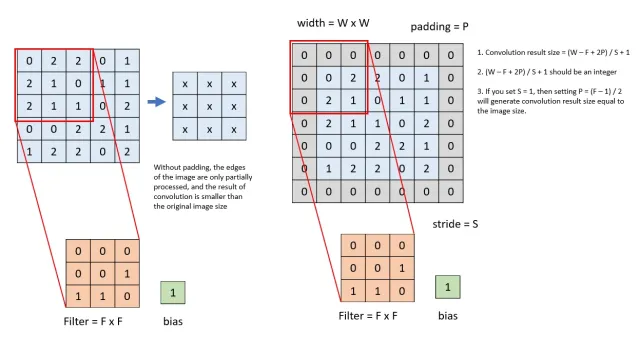

In [24]:
class CatDogCNN(nn.Module):
  def __init__(self):
    super().__init__()
    self.network = nn.Sequential(
        nn.Conv2d(in_channels=3, out_channels=16, kernel_size=3, padding=1),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2),

        nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, padding=1),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2),

        nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2),

        nn.AdaptiveAvgPool2d((4,4)),
        nn.Flatten(),
        nn.Linear(in_features=64*4*4, out_features=32),
        nn.ReLU(),
        nn.Linear(in_features=32, out_features=2),)

  def forward(self, x):
    return self.network(x)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = CatDogCNN().to(device)
print(model)

CatDogCNN(
  (network): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): AdaptiveAvgPool2d(output_size=(4, 4))
    (10): Flatten(start_dim=1, end_dim=-1)
    (11): Linear(in_features=1024, out_features=32, bias=True)
    (12): ReLU()
    (13): Linear(in_features=32, out_features=2, bias=True)
  )
)


In [25]:
device

device(type='cuda')

In [26]:
loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

In [29]:
best_accuracy = -1.0
train_loss = []
val_accuracies = []

Model_file = Path("cat_dog_model.pth")
epochs = 100

for epoch in range(epochs):
  model.train()
  total_loss =0.0

  for images, labels in train_loader:
    images, labels = images.to(device), labels.to(device)

    optimizer.zero_grad()
    outputs = model(images)
    loss = loss_function(outputs, labels)
    loss.backward()
    optimizer.step()

    total_loss += loss.item()


  average_loss = total_loss/len(train_loader)
  train_loss.append(average_loss)

  model.eval()
  correct = 0
  with torch.no_grad():
    for images, labels in val_loader:
      images, labels = images.to(device), labels
      outputs = model(images)
      predictions = outputs.argmax(dim=1).cpu()
      correct += (predictions == labels).sum().item()

  accuracy = correct/len(val_loader.dataset)
  val_accuracies.append(accuracy)
  if accuracy > best_accuracy:
    best_accuracy = accuracy
    torch.save(model.state_dict(), Model_file)

  print(f"Epoch {epoch+1}/{epochs} | Loss: {average_loss:.3f} "
        f"| Validation Accuracy: {accuracy:.3f}")
print(f"\nSaved best model: {Model_File} | Validation accuracy: {best_accuracy}")

Epoch 1/100 | Loss: 0.594 | Validation Accuracy: 0.643
Epoch 2/100 | Loss: 0.601 | Validation Accuracy: 0.662
Epoch 3/100 | Loss: 0.571 | Validation Accuracy: 0.686
Epoch 4/100 | Loss: 0.557 | Validation Accuracy: 0.696
Epoch 5/100 | Loss: 0.542 | Validation Accuracy: 0.705
Epoch 6/100 | Loss: 0.526 | Validation Accuracy: 0.672
Epoch 7/100 | Loss: 0.526 | Validation Accuracy: 0.710
Epoch 8/100 | Loss: 0.510 | Validation Accuracy: 0.715
Epoch 9/100 | Loss: 0.502 | Validation Accuracy: 0.716
Epoch 10/100 | Loss: 0.505 | Validation Accuracy: 0.690
Epoch 11/100 | Loss: 0.501 | Validation Accuracy: 0.714
Epoch 12/100 | Loss: 0.508 | Validation Accuracy: 0.703
Epoch 13/100 | Loss: 0.484 | Validation Accuracy: 0.712
Epoch 14/100 | Loss: 0.480 | Validation Accuracy: 0.737
Epoch 15/100 | Loss: 0.473 | Validation Accuracy: 0.729
Epoch 16/100 | Loss: 0.476 | Validation Accuracy: 0.705
Epoch 17/100 | Loss: 0.456 | Validation Accuracy: 0.726
Epoch 18/100 | Loss: 0.443 | Validation Accuracy: 0.710
E

NameError: name 'Model_File' is not defined

In [ ]:
#break till 10:25am IST